## Лабораторная работа №1 | Вариант 6

Выполнил: Демьянов Вячеслав, группа М8О-312БВ-24

### 1. Numpy

In [3]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [4]:
np.eye(3)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

2. Создайте матрицу 5х5 со значениями 1, 2, 3, 4 ниже диагонали

In [5]:
np.diag([1, 2, 3, 4], k=-1)

array([[0, 0, 0, 0, 0],
       [1, 0, 0, 0, 0],
       [0, 2, 0, 0, 0],
       [0, 0, 3, 0, 0],
       [0, 0, 0, 4, 0]])

3. Какой выход будет у данного скрипта

```python
# Author: Jake VanderPlas

print(sum(range(5),-1))
from numpy import *
print(sum(range(5),-1))
```

In [6]:
print(sum(range(5),-1))
from numpy import *
print(sum(range(5),-1))

9
10


Во встроенном sum -1 это начальное значение. После импорта sum заменяется на np.sum, где -1 это номер оси.

4. Как найти самое часто встречаемое значение между двумя массивами? 

In [7]:
a = np.array([5, 5, 5, 5, 5, 2, 2, 3])
b = np.array([2, 2, 3, 4])

values, counts = np.unique(np.concatenate([a, b]), return_counts=True)
print(values[counts.argmax()])

common = np.isin(values, np.intersect1d(a, b))
print(values[common][counts[common].argmax()])

5
2


Первое значение самое частое в обоих массивах вместе, второе самое частое среди тех, что есть в каждом из массивов.

5. Как игнорировать все warnings в numpy(не нужно так делать, но покажи)?

In [8]:
old = np.seterr(all='ignore')
print(np.array([1.0]) / 0)
np.seterr(**old);

[inf]


6. Реализуем функцию-генератор, которая генерирует 10 целых чисел и используем ее для построения массива

In [9]:
def generate():
    for x in range(10):
        yield x

np.fromiter(generate(), dtype=int, count=10)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

7. Создайте массив случайных чисел размером 10 и отсортируйте его

In [10]:
arr = np.random.random(10)
arr.sort()
arr

array([0.02740135, 0.09201715, 0.38738265, 0.42011503, 0.42925054,
       0.43953622, 0.55503296, 0.5629079 , 0.63445218, 0.98446267])

8. Создайте случайную матрицу 10х2 которая представляет собой декартовые координаты и преобразуйте их в полярные

In [11]:
xy = np.random.uniform(-1, 1, size=(10, 2))
x, y = xy[:, 0], xy[:, 1]

r = np.hypot(x, y)
theta = np.arctan2(y, x)

np.column_stack([r, theta])

array([[ 0.66480294, -0.31252723],
       [ 0.96583965,  1.67337737],
       [ 0.40065642, -1.40430088],
       [ 0.32876278, -2.01503555],
       [ 1.02561579, -2.67890585],
       [ 0.60238089,  1.62695967],
       [ 0.95013261,  1.49363602],
       [ 0.52005536,  0.51546661],
       [ 0.95239437,  1.96174606],
       [ 1.14672579,  2.48423106]])

9. Создайте структурированный массив который будет описывать пиксель(координату x, y и цвет r,g,b)

In [12]:
pixel = np.dtype([('x', np.int32), ('y', np.int32),
                  ('r', np.uint8), ('g', np.uint8), ('b', np.uint8)])

pixels = np.zeros(2, dtype=pixel)
pixels[0] = (10, 20, 255, 0, 0)
pixels

array([(10, 20, 255, 0, 0), ( 0,  0,   0, 0, 0)],
      dtype=[('x', '<i4'), ('y', '<i4'), ('r', 'u1'), ('g', 'u1'), ('b', 'u1')])

10. Как конвертировать тип массив от float32 в int32 in place?

In [13]:
a = np.array([1.5, 2.7, -3.2, 4.0], dtype=np.float32)
b = a.view(np.int32)
b[:] = a
print(b, b.dtype, np.shares_memory(a, b))

[ 1  2 -3  4] int32 True


astype(np.int32, copy=False) при разных типах создает копию, поэтому здесь view, чтоб память осталась той же

### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Набор данных описывает эффективность учеников в зависимости от некоторых факторов влияющих на обучение и окружение человека.

Файл: `student_perfomance.csv`

```
Hours_Studied - количество часов затраченное на обучение в неделю
Attendance - поцент посещенных занятий
Parental_Involvement - уровень участия родителей в обучении учащегося
Access_to_Resources - доступность ресурсов для обучения
Extracurricular_Activities - участие во внеклассных мероприятиях
Sleep_Hours - количество часов выделяемое на сон в день
Previous_Scores - оценка за первый экзамен
Motivation_Level - уровень мотивации
Internet_Access - доступ к интернету
Tutoring_Sessions - количество посещаемых репетиторских занятий в месяц.
Family_Income - доход семьи
Teacher_Quality - насколько качественно преподает учитель
School_Type - тип школы(частная, обычная)
Peer_Influence - влияние сверстников
Physical_Activity - физическая активность
Learning_Disabilities - наличие проблем с обучаемостью
Parental_Education_Level - уровень образования родителей
Distance_from_Home - дистанция от дома до школы
Gender - пол
Exam_Score - оценка на конечном экзамене
```

In [14]:
import pandas as pd

In [15]:
df = pd.read_csv('student_perfomance.csv')
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


1. Посчитайте среднее кол-во часов уделяемое на сон студентами

In [16]:
df['Sleep_Hours'].mean()

7.029060087785682

2. Сколько процентов студентов посещают внеклассовые активности?

In [17]:
(df['Extracurricular_Activities'] == 'Yes').mean() * 100

59.60345088542455

3. Правда ли, что в среднем девушки сдают экзамены лучше, чем мужчины

In [18]:
df.groupby('Gender')['Exam_Score'].mean()

Gender
Female    67.244898
Male      67.228894
Name: Exam_Score, dtype: float64

Нет, средние баллы почти равны

4. Выведите 25 и 75 перцентили времени сна студентов

In [19]:
df['Sleep_Hours'].quantile([0.25, 0.75])

0.25    6.0
0.75    8.0
Name: Sleep_Hours, dtype: float64

5. Правда ли, что те, кто спит больше(75 перцентиль и выше) сдает экзамен лучше, чем студенты с недосыпом(25 перцентиль и меньше)

In [20]:
q25, q75 = df['Sleep_Hours'].quantile([0.25, 0.75])

print(df[df['Sleep_Hours'] >= q75]['Exam_Score'].mean())
print(df[df['Sleep_Hours'] <= q25]['Exam_Score'].mean())

67.18704746580853
67.28109243697479


Нет, те, кто спит больше, набирают столько же или даже чуть меньше

6. Влияет ли физическая активность на результаты экзамена?

In [21]:
print(df['Physical_Activity'].corr(df['Exam_Score']))
df.groupby('Physical_Activity')['Exam_Score'].agg(['mean', 'count'])

0.027824436180257425


,mean,count
Physical_Activity,,
0,67.521739,46
1,66.969121,421
2,67.185003,1627
3,67.196071,2545
4,67.313016,1575
5,67.603878,361
6,68.093750,32


Почти не влияет. Корреляция меньше 0.03, а в самых больших группах средние почти одинаковые

7. Правда ли, что слуденты, чьи родители имеют высшее образование(College || Postgraduate), сдают экзамены лучше, чем остальные?

In [22]:
known = df.dropna(subset=['Parental_Education_Level']) # не учитываем пропуски
higher = known['Parental_Education_Level'].isin(['College', 'Postgraduate'])

print(known[higher]['Exam_Score'].mean())
print(known[~higher]['Exam_Score'].mean())

67.57528840315726
66.89357741234875


Да, но разница небольшая

8. Как влияет участие родителей на результаты экзаменов

In [23]:
df.groupby('Parental_Involvement')['Exam_Score'].mean().reindex(['Low', 'Medium', 'High'])

Parental_Involvement
Low       66.358265
Medium    67.098156
High      68.092767
Name: Exam_Score, dtype: float64

Чем больше родители участвуют, тем выше балл

9. Правда ли, что в семьях с доходом больше среднего дети сдают экзамены лучше?

In [24]:
print(df[df['Family_Income'] == 'High']['Exam_Score'].mean())
print(df[df['Family_Income'] != 'High']['Exam_Score'].mean())

67.84239558707644
67.09142000749344


Да, но разница небольшая

10. Посчитайте долю студентов сдавших экзамен на более чем 70 баллов в семьях с низким доходом и отсутствием доступа к интернету

In [25]:
group = df[(df['Family_Income'] == 'Low') & (df['Internet_Access'] == 'No')]
(group['Exam_Score'] > 70).mean()

0.08056872037914692

### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

In [26]:
import matplotlib.pyplot as plt

1. Правда ли, что количество часов затрачиваемых на сон распределено примерно нормально?

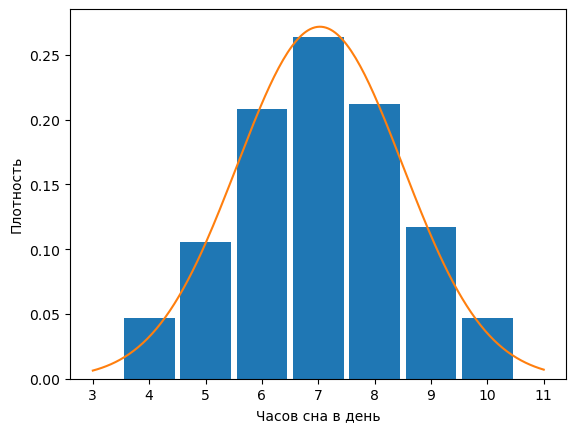

-0.023805436886157025 -0.5036974317213572


In [27]:
sleep = df['Sleep_Hours']
mu, sigma = sleep.mean(), sleep.std()

plt.hist(sleep, bins=np.arange(3.5, 11.5), density=True, rwidth=0.9)
x = np.linspace(3, 11, 200)
plt.plot(x, np.exp(-(x - mu) ** 2 / (2 * sigma ** 2)) / (sigma * np.sqrt(2 * np.pi)))
plt.xlabel('Часов сна в день')
plt.ylabel('Плотность')
plt.show()

print(sleep.skew(), sleep.kurt())

Да, примерно нормально. Форма симметричная и кривая хорошо ложится на гистограмму

2. Постройте гистограмму распределения количества часов затрачиваемых на обучение среди мальчиков и девочек

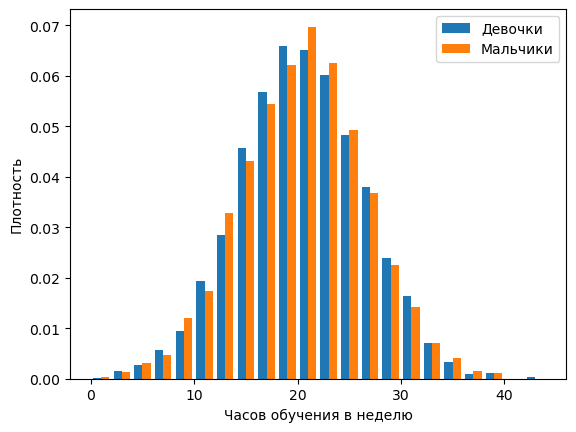

In [28]:
female = df[df['Gender'] == 'Female']['Hours_Studied']
male = df[df['Gender'] == 'Male']['Hours_Studied']

plt.hist([female, male], bins=np.arange(0, 46, 2), density=True, label=['Девочки', 'Мальчики'])
plt.xlabel('Часов обучения в неделю')
plt.ylabel('Плотность')
plt.legend()
plt.show()

Плотность взята потому, что мальчиков в данных больше

3. Как зависит результат конечного экзамена от результата первого экзамена

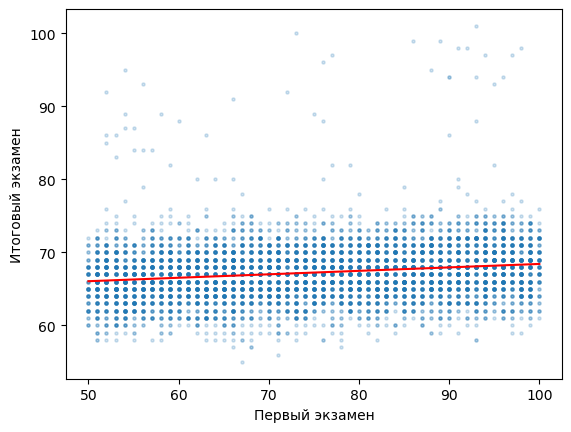

0.04730191992425659 0.1750790870229109


In [29]:
slope, intercept = np.polyfit(df['Previous_Scores'], df['Exam_Score'], 1)

plt.scatter(df['Previous_Scores'], df['Exam_Score'], s=5, alpha=0.2)
x = np.array([50, 100])
plt.plot(x, slope * x + intercept, color='red')
plt.xlabel('Первый экзамен')
plt.ylabel('Итоговый экзамен')
plt.show()

print(slope, df['Previous_Scores'].corr(df['Exam_Score']))

Зависимость положительная, но слабая, корреляция около 0.175

4. Постройте box plot отображающий распределение количества сна детей сдавших экзамены на оценку ниже и выше 85 баллов

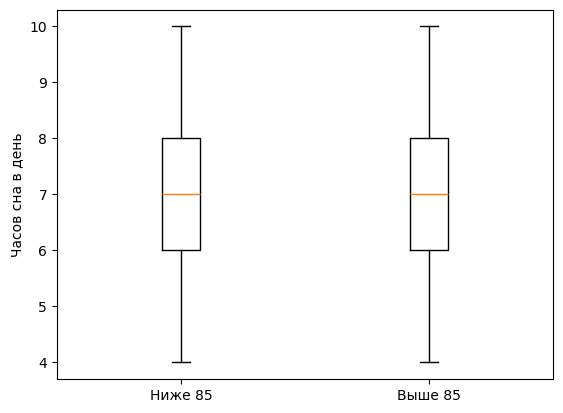

6572 34


In [30]:
below = df[df['Exam_Score'] < 85]['Sleep_Hours']
above = df[df['Exam_Score'] > 85]['Sleep_Hours']

plt.boxplot([below, above])
plt.xticks([1, 2], ['Ниже 85', 'Выше 85'])
plt.ylabel('Часов сна в день')
plt.show()

print(len(below), len(above))

Распределения одинаковые: медиана 7 часов, квартили 6 и 8. Больше 85 набрали только 34 человека

5. Правда ли, что количество посещаемых занятий с репетитором в месяц напрямую влияет на балл в конечном экзамене?

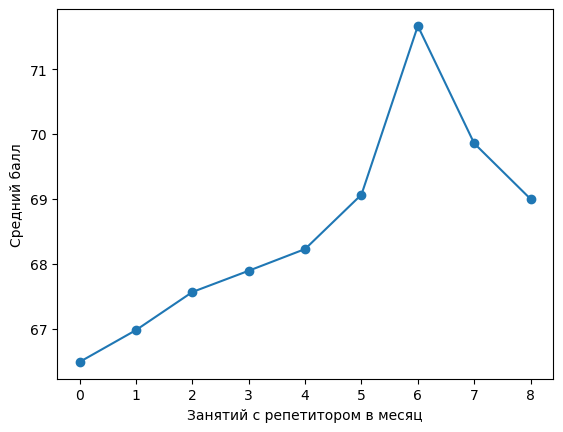

Tutoring_Sessions
0    1513
1    2179
2    1649
3     836
4     301
5     103
6      18
7       7
8       1
Name: count, dtype: int64
0.15652518539225324
0.49485531414622896


In [31]:
means = df.groupby('Tutoring_Sessions')['Exam_Score'].mean()

plt.plot(means.index, means.values, marker='o')
plt.xlabel('Занятий с репетитором в месяц')
plt.ylabel('Средний балл')
plt.show()

print(df['Tutoring_Sessions'].value_counts().sort_index())
print(df['Tutoring_Sessions'].corr(df['Exam_Score']))
print(np.polyfit(df['Tutoring_Sessions'], df['Exam_Score'], 1)[0])

Связь есть, но слабая, с корреляцией около 0.16; одно занятие в среднем дает примерно 0.5 балла. При 6-8 занятиях студентов очень мало (18, 7 и 1), поэтому там график скачет. Связь видна, но доказать прямое влияние нельзя 

6. Как физическая активность влияет на успеваемость?

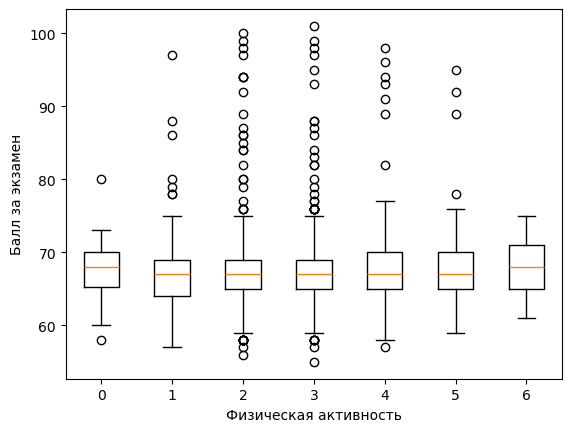

In [32]:
levels = sorted(df['Physical_Activity'].unique())
groups = [df[df['Physical_Activity'] == level]['Exam_Score'] for level in levels]

plt.boxplot(groups)
plt.xticks(range(1, len(levels) + 1), levels)
plt.xlabel('Физическая активность')
plt.ylabel('Балл за экзамен')
plt.show()

Почти не влияет. Медианы 67-68 баллов на всех уровнях, а разброс внутри групп намного больше разницы между ними

7. Постройте HeatMap где ось Х - процент посещаемость, Y - количество занятий с репетитором, а Z - балл за итоговый экзамен*

\* Задание на доп. балл

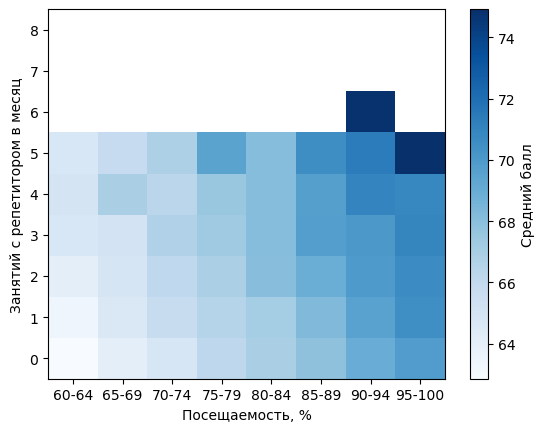

In [34]:
labels = ['60-64', '65-69', '70-74', '75-79', '80-84', '85-89', '90-94', '95-100']
attendance = pd.cut(df['Attendance'], bins=[60, 65, 70, 75, 80, 85, 90, 95, 101], right=False, labels=labels)

means = df.pivot_table(index='Tutoring_Sessions', columns=attendance, values='Exam_Score', aggfunc='mean', observed=False)
counts = df.pivot_table(index='Tutoring_Sessions', columns=attendance, values='Exam_Score', aggfunc='count', observed=False)
means = means.where(counts >= 5)

plt.imshow(means, origin='lower', aspect='auto', cmap='Blues')
plt.xticks(range(len(labels)), labels)
plt.yticks(range(len(means.index)), means.index)
plt.xlabel('Посещаемость, %')
plt.ylabel('Занятий с репетитором в месяц')
plt.colorbar(label='Средний балл')
plt.show()